In [ ]:
#@title Libraries
import sys
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import LineString, Point, MultiPoint
from shapely.affinity import rotate
import pandas as pd
from scipy.optimize import fsolve
from scipy.optimize import minimize_scalar
from google.colab import output
# !pip install ezdxf
# import ezdxf

pd.set_option("display.width", 200)          # or 300, 500...
pd.set_option("display.max_columns", None)   # show all columns

Meanline design of Francis Turbines, based on the Bovet method (Contribution à l'étude du tracé d'aubage d'une turbine à réaction du type Francis - T. Bovet).

By Rodolfo Dias.

Meridional contour design based on: https://github.com/newton-raphson/francis-runner-design

In [ ]:
#@title Functions

class out:
    def __init__(self, **kwargs):
        self.__dict__.update(kwargs)

######################################################
######################################################
######################################################

def cm_factor(span, no):
    # Hub: span=0 | Shroud: span=1
    if no <= 0.3:
      result = 1
    else:
      result = (35250 - np.sqrt(-1e8*span**2 - 4.85e7*span + 689074419))/10000
    return result

def curve(x, l):
    x = x / l
    return 3.08 * (1 - x)**(3/2) * x**0.5

def r2i(no):
    return (9.133 * no**4
            - 16.61 * no**3
            + 11.34 * no**2
            - 3.707 * no
            + 0.974)

def r1e(no):
    return (-125.6 * no**5
            + 299.4 * no**4
            - 278.0 * no**3
            + 126.3 * no**2
            - 28.52 * no
            + 3.674)

def arc_length(alpha1, alpha2, chord):
    dtheta = np.deg2rad(abs(alpha2 - alpha1))
    return chord * dtheta / (2 * np.sin(dtheta / 2))

######################################################
######################################################
######################################################

def distance_to_rotated_line(array, pivot, target, angle):
    # Create a line through 2 points
    p1, p2 = np.array(p1), np.array(p2)
    line = LineString([p1, p2])
    if isinstance(pivot, np.ndarray):
        pivot = tuple(pivot.flatten())
    # Rotate the line around a pivot point by a angle
    rotated_line = rotate(line, angle, origin=(0,0), use_radians=False)
    # Measure distance from a target point to rotated line
    target_pt = Point(target)
    return target_pt.distance(rotated_line)

######################################################
######################################################
######################################################

def naca4digit(c, ang, r, t, n=100):
    x = np.linspace(0, 1, n)
    yt = 5 * t * (
        0.2969*np.sqrt(x)
        - 0.1260*x
        - 0.3516*x**2
        + 0.2843*x**3
        - 0.1036*x**4
    )
    xu = c * x - c
    yu = -c * yt
    xl = c * x - c
    yl = c * yt
    def transform(X, Y):
      xr = X*np.cos(ang) - Y*np.sin(ang)
      yr = - X*np.sin(ang) - Y*np.cos(ang) + r
      return xr, yr
    xu, yu = transform(xu, yu)
    xl, yl = transform(xl, yl)
    upper_surf = LineString(np.column_stack((xu, yu)))
    lower_surf = LineString(np.column_stack((xl, yl)))
    rot_point = Point(
        - c/2*np.cos(ang),
        r + c/2*np.sin(ang)
        )
    return upper_surf, lower_surf, rot_point

######################################################
######################################################
######################################################

def interx_shapely(x1, y1, x2, y2):
    line1 = LineString(np.column_stack((x1, y1)))
    line2 = LineString(np.column_stack((x2, y2)))

    intersection = line1.intersection(line2)

    if intersection.is_empty:
        return np.zeros((2, 0))

    # Extract points regardless of whether it's one point or many
    if intersection.geom_type == 'Point':
        return np.array([[intersection.x], [intersection.y]])
    elif intersection.geom_type == 'MultiPoint':
        return np.array([p.coords[0] for p in intersection.geoms]).T

    return intersection

######################################################
######################################################
######################################################

def merid_dims(Vo, H, nr, N):

  # constants
  g = 9.81
  v2eo = 0.27
  x2e = 0.5

  # --- dimensionless ---
  no = (nr * np.sqrt(Vo / np.pi)) / ((2 * g * H) ** (3/4))

  bo = 0.8 * (2 - no) * no
  roi = 0.7 + 0.16 / (no + 0.08)
  ymi = roi
  rli = 0.493 / (no ** (2/3))

  if no < 0.275:
      roe = 0.493 / (no ** (2/3))
  else:
      roe = 1.255 - 0.3 * no

  li = 3.2 + 3.2 * (2 - no) * no
  le = 2.4 - 1.9 * (2 - no) * no

  y2e = roe - 1
  y2ebyyme = curve(x2e, le)
  yme = y2e / y2ebyyme
  rme = roe - yme

  # --- dimensional ---
  R2e = ((Vo / np.pi) / (v2eo * nr)) ** (1/3)

  Bo = bo * R2e
  Roi = roi * R2e
  Ymi = ymi * R2e
  Rli = rli * R2e
  Roe = roe * R2e
  Li = li * R2e
  Le = le * R2e
  X2e = x2e * R2e
  Y2e = y2e * R2e
  Yme = yme * R2e
  Rme = rme * R2e

  return out(no=no, R2e=R2e, Bo=Bo, Roi=Roi, Ymi=Ymi, Rli=Rli, Roe=Roe,
          Li=Li, Le=Le, X2e=X2e, Y2e=Y2e, Yme=Yme, Rme=Rme)

######################################################
######################################################
######################################################

def merid_lines(dims, n=1000):
    x1 = np.zeros(n)
    y1 = np.zeros(n)
    x2 = np.zeros(n)
    y2 = np.zeros(n)
    dif = np.zeros(n)

    # --- HUB ---
    p = dims.Li / 4
    q = p / n
    b = 0

    for i in range(n):
        x1[i] = b
        y1 = dims.Ymi * curve(x1, dims.Li)   # vectorized like MATLAB
        b += q

    x1 = -x1
    y1 = -y1

    x1 += (dims.Le + dims.Bo)
    y1 += dims.Roi
    hub = LineString(np.column_stack((y1, x1)))

    # --- SHROUD ---
    p = dims.Le
    q = p / n
    b = 0

    for i in range(n):
        x2[i] = b
        y2 = dims.Yme * curve(x2, dims.Le)
        b += q

    x2 = -x2
    y2 = -y2

    x2 += dims.Le
    y2 += dims.Roe
    shroud = LineString(np.column_stack((y2, x2)))

    # --- STREAMLINES ---
    x = np.zeros((N, n))
    y = np.zeros((N, n))
    SL = []

    for i in range(N):
        x[i, :] = x1 + (x2 - x1) * (i + 1) / (N + 1)
        y[i, :] = y1 + (y2 - y1) * (i + 1) / (N + 1)
        SL.append(LineString(np.column_stack((y[i, :], x[i, :]))))

    # --- INTERSECTIONS ---
    x_line = np.arange(0, dims.Le + dims.Bo, 0.001)

    # LE1
    y_line = np.full_like(x_line, dims.Rli)
    LE1 = interx_shapely(y_line, x_line, y1, x1)

    # LE2
    y_line = np.full_like(x_line, dims.R2e * r1e(dims.no))
    Le2 = interx_shapely(y_line, x_line, y2, x2)
    idx = np.argmax(Le2[1, :])
    LE2 = Le2[:, idx]

    # TE1
    y_line = np.full_like(x_line, dims.R2e * r2i(dims.no))
    TE1 = interx_shapely(y_line, x_line, y1, x1)

    # TE2
    y_line = np.full_like(x_line, dims.R2e)
    Te2 = interx_shapely(y_line, x_line, y2, x2)
    idx = np.argmin(Te2[1, :])
    TE2 = Te2[:, idx]

    # --- LEADING EDGE CURVE ---
    xl = np.zeros(n)
    yl = np.zeros(n)

    a = (LE1[1, 0] - LE2[1]) / ((LE1[0, 0] - LE2[0])**2)
    p = LE2[0] - LE1[0, 0]
    q = p / (n - 1)
    r = LE1[0, 0]

    for i in range(n):
        xl[i] = r
        yl[i] = a * (xl[i] - LE2[0])**2 + LE2[1]
        r += q
    LE_line = LineString(np.column_stack((xl, yl)))

    # --- TRAILING EDGE CURVE ---
    xt = np.zeros(n)
    yt = np.zeros(n)

    a = (TE1[1, 0] - TE2[1]) / ((TE1[0, 0] - TE2[0])**2)
    p = abs(TE2[0] - TE1[0, 0])
    q = p / (n - 1)
    r = TE1[0, 0]

    for i in range(n):
        xt[i] = r
        yt[i] = a * (xt[i] - TE2[0])**2 + TE2[1]
        r += q
    TE_line = LineString(np.column_stack((xt, yt)))

    # ----- Leading and Trailing edge calculation points -----
    # Index = 0: Hub | Index = M: Meanline | Index = S: Shroud
    S = N+1
    M = int(np.ceil(S/2))
    LEpts = []
    TEpts = []

    # Points at hub:
    LEpts.append(Point(LE1[0, 0], LE1[1, 0]))
    TEpts.append(Point(TE1[0, 0], TE1[1, 0]))

    # Points between hub and shroud:
    for i in range(N):
        LEpts.append(LE_line.intersection(SL[i]))
        TEpts.append(TE_line.intersection(SL[i]))

    # Points at shroud:
    LEpts.append(Point(LE2[0], LE2[1]))
    TEpts.append(Point(TE2[0], TE2[1]))

    # Passage at LE and TE
    bLE = LEpts[M].distance(hub) + LEpts[M].distance(shroud)
    bTE = TEpts[M].distance(hub) + TEpts[M].distance(shroud)

    # Distance between each LE and TE points
    dist = [p1.distance(p2) for p1, p2 in zip(LEpts, TEpts)]

    return out(x1=x1, y1=y1, x2=x2, y2=y2, x=x, y=y,
               xl=xl, yl=yl, xt=xt, yt=yt, TE_line=TE_line,
               LE_line=LE_line, bLE=bLE, bTE=bTE,
               hub=hub, shroud=shroud, LEpts=LEpts,
               TEpts=TEpts, SL=SL, M=M, S=S, dist=dist)

######################################################
######################################################
######################################################

def VelTriang(dims, lins, Vo, H, nr, Z, chord, tkns, N, zs, f, rho=1000, g=9.81, hi=.985):
  # Notice here that "hi" is the assumed efficiency, according to Bovet
  # RN: Runner | WG: Wicket Gate | LE: Leading Edge | TE: Trailing edge
  ptloss = 0.05*rho*g*H # Draft tube total pressure loss (taken to be 5% of effective head)
  idx = np.linspace(0, 1, lins.S+1)

  # Adimensionalization factor
  adim = np.sqrt(2*g*H)

  # Checking if N is odd:
  if (N % 2 != 0) == False:
    sys.exit("Error: 'N' MUST be odd. Stopping run.")

  b = np.zeros(3) # Passage at each station
  b[0] = lins.x1[0] - lins.x2[0]
  b[1] = lins.bLE
  b[2] = lins.bTE

  # Variables that are different on the spanwise direction:
  R, u, c, cm, cu, w, wu, beta = np.zeros((8, 3, (lins.S+1)))
  # coordinate indexing = (streamwise, spanwise)
  # WG-TE = (0, :) | RN-LE = (1, :) | RN-TE =  (2, :)
  # hub =   (:, 0) | mean =  (:, lins.M) | shroud = (:, lins.S)
  pout = np.zeros(lins.S+1)

  R[0, :] = lins.y2[0] * f # Radius of the WG's TE
  for i in range(lins.S+1):
    R[1, i] = lins.LEpts[i].x # Radius of the points at LE
    R[2, i] = lins.TEpts[i].x # Radius of the points at TE

  # Meridional velocities at meanline
  cm[:, lins.M] = Vo / (b[:]*R[:, lins.M]*2*np.pi*adim)

  # Meridional velocities at hub and shroud
  # Because of the channel's curvature, flow is faster near outer radii (shroud)
  # and slower near inner radii (hub)
  cm[0, :] = cm[0, lins.M]
  cm[1, :] = cm_factor(idx[:], dims.no) * cm[1, lins.M]

  # Bovet considers meridional velocity constant across the TE of the runner
  cm[2, :] = cm[2, lins.M] # Meridional velocity at TE

  # Blade tangential velocities
  u = nr*R / adim
  w[2, :] = u[2, :]

  # Absolute tangential velocities
  alpha0 = np.arctan(2*u[0, lins.M]*cm[0, lins.M]/hi)
  cu[0, :] = cm[0, :] / np.tan(alpha0)
  # Leading edge, applying free vortex condition
  cu[1, :] = R[0, :]/R[1, :] * cu[0, :]
  # Trailing edge
  cu[2, :] = u[2, :] - np.sqrt(abs(w[2, :]**2 - cm[2, :]**2))

  # Runner blade angles
  beta[1, :] = np.arctan(cm[1, :] / (u[1, :] - cu[1, :]))
  beta[2, :] = np.arcsin(cm[2, :]/w[2, :])

  c = np.sqrt(cm**2 + cu**2) # Absolute velocities
  wu = u - cu # Relative tangential velocities
  w = np.sqrt(wu**2 + cm**2) # Relative velocities

  pout = ptloss - 1/2*rho*(c[2, :]*adim)**2 - rho*g*zs # Static (gauge) pressure at runner outlet
  if (min(pout) + 101325) < 0:
    print('Warning: Absolute pressure at runner outlet reached negative values, decrease suction height to avoid cavitation')

  # --- Calculating the spacing between WGs ---
  # Here we basically draw the centerline of the WG and rotate by the pitch of the WGs,
  # pivoting around the machine axis, then measure the distance between the TE point to that rotated line.
  # In the end, you will have to check with the geometry to see if the value of "d" is respected
  p1 = Point(0, R[0, lins.M])
  p2 = Point(-np.cos(alpha0)*chord, R[0, lins.M] + np.sin(alpha0)*chord)
  pitch = -360 / Z
  d1 = Vo / c[0, lins.M] / b[0] / Z / adim
  uppersurf, lowersurf, rot_point = naca4digit(chord, alpha0, R[0, lins.M], tkns)
  rotated_uppersurf = rotate(uppersurf, pitch, origin=(0,0), use_radians=False)
  rotated_lowersurf = rotate(lowersurf, pitch, origin=(0,0), use_radians=False)
  d2 = uppersurf.distance(rotated_lowersurf)

  # Suggesting a number of wicket gates and runner blades, according to Nachleba
  Z_WG1 = np.sqrt(2000*R[0, lins.M])/4 + 4
  Z_WG2 = np.sqrt(2000*R[0, lins.M])/4 + 6
  Z_R1 = 10/u[1, lins.M]
  Z_R2 = 12/u[1, lins.M]

  # Reynolds number
  D = 2*R[2, lins.S] # Characteristic diameter (turbine outlet diameter)
  U = nr*D # Characteristic velocity (Blade speed)
  mu = 1.002e-3 # Kinematic viscosity of water
  Re = rho*U*D/mu

  # meanline = {
  #     'c': np.round(c*adim, 2),
  #     'cm': np.round(cm[:, 1]*adim, 2),
  #     'cu': np.round(cu*adim, 2),
  #     'u': np.round(u*adim, 2),
  #     'w': np.round(w*adim, 2),
  #     'wu': np.round(wu*adim, 2)
  # }

  P = rho*Vo*g*H/1000 # Power in kW

  # Create DataFrames
  # df1 = pd.DataFrame(meanline)
  # df1.index = ['Wicket Gate', 'Runner LE', 'Runner TE']
  LE_rad, LE_ang = WG_dims(R[0, lins.M], chord, alpha0)
  data=np.array([
      [np.rad2deg(LE_ang), LE_rad],
      [np.rad2deg(alpha0), R[0, lins.M]]
  ])
  df = pd.DataFrame(
    data=np.round(data, 3),
    columns=["Angle", "Radius"], # Column names
    index=["LE", "TE"] # Row names
  )
  LEstr = []
  TEstr = []
  for i in range(lins.S+1):
    LEstr.append(f'{np.round(np.rad2deg(beta[1, i]), 2)}° @ R{np.round(R[1, i], 2)}')
    TEstr.append(f'{np.round(np.rad2deg(beta[2, i]), 2)}° @ R{np.round(R[2, i], 2)}')
  angles = {
      f"{i}": (LEstr[i], TEstr[i])
      for i in range(lins.S + 1)
  }
  df2 = pd.DataFrame(angles).T
  df2.columns = ['Leading Edge', 'Trailing Edge']

  print()
  print('---------- Machines main parameters ----------')
  print(f'''
  Total available power: {P:.2f} kW
  Average static (gauge) pressure at runner outlet: {np.mean(pout):.2f} Pa
  Characteristic velocity (U): {U:.2f} m/s
  Characteristic diameter (D): {D:.2f} m
  Dynamic viscosity (mu): {mu:.2e} Pa.s
  Reynolds number (rho*U*D/mu): {Re:.2e}

  Suggested number of wicket gates: {Z_WG1:.0f} - {Z_WG2:.0f}
  Suggested number of runner blades: {Z_R1:.0f} - {Z_R2:.0f}

  Meanline dimensions:
  LE mean radius: {R[1, lins.M]:.3f} m
  TE mean radius: {R[2, lins.M]:.3f} m
  Inlet passage: {b[0]:.3f} m
  Outlet radius: {lins.y2[0]:.3f} m

  Selected number of wicket gates: {Z}
  Desired WG passage: {d1:.4f} m
  Effective WG passage: {d2:.4f} m
  ''')
  # print()
  # print('---------- Meanline flow variables ----------')
  # print(df1)
  print()
  print('---------- Wicket Gate ----------')
  print(df)
  print()
  print('---------- Runner blade angles ----------')
  print(df2)
  print()

  return out(adim=adim, c=c, cm=cm, cu=cu, u=u, w=w, wu=wu, alpha0=alpha0, beta=beta, R=R,
             uppersurf=uppersurf, lowersurf=lowersurf, rotated_uppersurf=rotated_uppersurf,
             rotated_lowersurf=rotated_lowersurf, rot_point=rot_point, pitch=pitch, b=b, Z=Z)

######################################################
######################################################
######################################################

def partLoad(Vo, Loads, vels, chord):
  Q_part = Vo*Loads
  best_angles = []
  best_errors = []
  for i, Q in enumerate(Q_part):
  # Find an WG opening angle that creates a incidence angle (beta1) at meanline equal to nominal condition
    def objective(ang):
      rot_us = rotate(vels.uppersurf, ang, origin=vels.rot_point, use_radians=True)
      rot_ls = rotate(vels.lowersurf, ang, origin=vels.rot_point, use_radians=True)
      rot_ls2 = rotate(rot_ls, vels.pitch, origin=(0, 0), use_radians=False)
      d = rot_us.distance(rot_ls2)
      R = np.sqrt((vels.rot_point.y - chord/2*np.sin(ang))**2 + (chord/2*np.cos(ang) + vels.rot_point.x)**2)
      cm0 = Q / (vels.b[0]*R*2*np.pi*vels.adim)
      cm1 = Q / (vels.b[1]*vels.R[1, lins.M]*2*np.pi*vels.adim)
      cu0 = cm0 / np.tan(vels.alpha0 - ang)
      cu1 = R/vels.R[1, lins.M] * cu0
      beta1 = np.arctan(cm1 / (vels.u[1, lins.M] - cu1))
      return abs(beta1 - vels.beta[1, lins.M])

    result = minimize_scalar(
        objective,
        bounds=(-np.pi/2, np.pi/2),
        method="bounded"
    )
    best_angles.append(result.x)
    best_errors.append(result.fun)

  TE_ang = vels.alpha0 - best_angles
  TE_rad = np.sqrt((vels.rot_point.y - chord/2*np.sin(TE_ang))**2 + (chord/2*np.cos(TE_ang) + vels.rot_point.x)**2)
  LE_rad = np.zeros_like(TE_ang)
  LE_ang = np.zeros_like(TE_ang)
  for i in range(len(TE_ang)):
    LE_rad[i], LE_ang[i] = WG_dims(TE_rad[i], chord, TE_ang[i])
  TE_ang = np.rad2deg(TE_ang)
  LE_ang = np.rad2deg(LE_ang)
  tab = pd.DataFrame(
    [(100*Loads), Q_part, np.round(TE_ang, 2), np.round(TE_rad, 4), np.round(LE_ang, 2), np.round(LE_rad, 4)],
    index=['Load (%)', 'Q_part (m³/s)', 'WG TE Angle (deg)', 'WG TE Radius (m)', 'WG LE Angle (deg)', 'WG LE Radius (m)']
  ).T
  print()
  print('---------- Partial loads ----------')
  print(tab)
  return out(Q_part=Q_part, TE_ang=TE_ang)

######################################################
######################################################
######################################################

def plotmerid(lins):
  plt.figure()
  plt.plot(lins.y1, lins.x1)
  plt.plot(lins.y2, lins.x2)
  for i in range(N):
    plt.plot(lins.y[i, :], lins.x[i, :], 'g')
  plt.title("Meridional plane")
  for i in range(len(lins.LEpts)):
    plt.plot(lins.LEpts[i].x, lins.LEpts[i].y, '*')
  for i in range(len(lins.TEpts)):
    plt.plot(lins.TEpts[i].x, lins.TEpts[i].y, '*')
  plt.plot(lins.xl, lins.yl)
  plt.plot(lins.xt, lins.yt)
  plt.text(lins.y1[-1], 0, f'{0}', color='red', bbox=dict(facecolor='white', edgecolor='black'))
  for i in range(N):
    plt.text(lins.y[i, -1], 0, f'{i+1}', color='red', bbox=dict(facecolor='white', edgecolor='black'))
  plt.text(lins.y2[-1], 0, f'{lins.S}', color='red', bbox=dict(facecolor='white', edgecolor='black'))
  plt.axis('equal')
  plt.grid()
  plt.show()

######################################################
######################################################
######################################################

def plotWG(vels, ang_deg):
  plt.figure()

  for i, ang in enumerate(ang_deg):
    delta_ang = ang - np.rad2deg(vels.alpha0)
    uppersurf1 = rotate(vels.uppersurf, -delta_ang, origin=vels.rot_point, use_radians=False)
    lowersurf1 = rotate(vels.lowersurf, -delta_ang, origin=vels.rot_point, use_radians=False)
    uppersurf2 = rotate(uppersurf1, vels.pitch, origin=(0, 0), use_radians=False)
    lowersurf2 = rotate(lowersurf1, vels.pitch, origin=(0, 0), use_radians=False)
    us1x, us1y = uppersurf1.xy
    ls1x, ls1y = lowersurf1.xy
    us2x, us2y = uppersurf2.xy
    ls2x, ls2y = lowersurf2.xy
    line, = plt.plot(us1x, us1y, label=f"{ang:.1f}°")
    color = line.get_color()
    plt.plot(ls1x, ls1y, color=color, label="_nolegend_")
    plt.plot(us2x, us2y, color=color, label="_nolegend_")
    plt.plot(ls2x, ls2y, color=color, label="_nolegend_")

  plt.axis('equal')
  plt.grid()
  plt.title('Wicket Gate')
  plt.legend(title="Angle")
  plt.show()

######################################################
######################################################
######################################################

def WG_dims(rad, chord, ang):
  wg_vec = np.array([-np.cos(ang)*chord, np.sin(ang)*chord])
  LE_vec = np.array([wg_vec[0], rad+wg_vec[1]])
  LE_rad = np.sqrt(LE_vec[0]**2 + LE_vec[1]**2)
  LE_normal = np.array([-LE_vec[1], LE_vec[0]])
  LE_ang = np.arccos(np.dot(wg_vec, LE_normal) / (LE_rad*chord))
  return LE_rad, LE_ang

######################################################
######################################################
######################################################

def dxfCreator(vels, ang_deg):
  doc = ezdxf.new()
  msp = doc.modelspace()
  for i, ang in enumerate(ang_deg):
    delta_ang = ang - np.rad2deg(vels.alpha0)
    uppersurf1 = rotate(vels.uppersurf, delta_ang, origin=vels.rot_point, use_radians=False)
    lowersurf1 = rotate(vels.lowersurf, delta_ang, origin=vels.rot_point, use_radians=False)
    msp.add_lwpolyline(list(uppersurf1.coords))
    msp.add_lwpolyline(list(lowersurf1.coords))
  doc.saveas("lines.dxf")

######################################################
######################################################
######################################################

def printdata(lins, dims):
  print('---------- Runner main dimensions ----------')
  print(f'''
  Inlet radius: {dims.Roe:.3f} m
  Outlet radius: {dims.R2e:.3f} m
  Hub radius: {dims.Roi:.3f} m
  Throat raidus: {dims.Rme:.3f} m
  Shroud length: {dims.Le:.3f} m
  Hub length: {dims.Li/4:.3f} m
  Passage length: {dims.Bo:.3f} m

  Hub LE point (x,y): ({lins.LEpts[0].x:.3f}, {lins.LEpts[0].y:.3f})
  Shroud LE point (x,y): ({lins.LEpts[lins.S].x:.3f}, {lins.LEpts[lins.S].y:.3f})
  Hub TE point (x,y): ({lins.TEpts[0].x:.3f}, {lins.TEpts[0].y:.3f})
  Shroud TE point (x,y): ({lins.TEpts[lins.S].x:.3f}, {lins.TEpts[lins.S].y:.3f})

  Hub start point (x,y): ({lins.y1[0]:.3f}, {lins.x1[0]:.3f})
  Hub end point (x,y): ({lins.y1[-1]:.3f}, {lins.x1[-1]:.3f})
  Shroud start point (x,y): ({lins.y2[0]:.3f}, {lins.x2[0]:.3f})
  Shroud end point (x,y): ({lins.y2[-1]:.3f}, {lins.x2[-1]:.3f})
  ''')

def plotVelTriang(vels, lins):
  fig, ax = plt.subplots(2, 1, figsize=(6, 5))
  spans = np.array([0, lins.M, lins.S])
  colors = ['b', 'r', 'g']
  labels = ['Hub', 'Mid', 'Shroud']
  cu, cm, wu, u = np.zeros((4, 3))
  cu[:] = vels.cu[1, spans[:]]*vels.adim
  wu[:] = vels.wu[1, spans[:]]*vels.adim
  cm[:] = vels.cm[1, spans[:]]*vels.adim
  u[:] = vels.u[1, spans[:]]*vels.adim

  ax[0].set_title("Leading Edge")
  for i in range(3):
    ax[0].quiver(-cu[i], cm[i], u[i], 0, label=labels[i], color=colors[i], angles='xy', scale_units='xy', scale=1) # u
    ax[0].quiver(0, cm[i], 0, -cm[i], color=colors[i], angles='xy', scale_units='xy', scale=1) # cm
    ax[0].quiver(-cu[i], cm[i], cu[i], -cm[i], color=colors[i], angles='xy', scale_units='xy', scale=1) # c
    ax[0].quiver(wu[i], cm[i], -wu[i], -cm[i], color=colors[i], angles='xy', scale_units='xy', scale=1) # w

  ax[0].set_xlim(-max(cu)*1.1, max(wu)*1.3)
  ax[0].set_ylim(0, max(cm)*1.1)
  ax[0].set_aspect('equal')
  ax[0].set_xlabel('Tangential (m/s)')
  ax[0].set_ylabel('Meridional (m/s)')
  ax[0].legend(loc='lower right')

  cu[:] = vels.cu[2, spans[:]]*vels.adim
  wu[:] = vels.wu[2, spans[:]]*vels.adim
  cm[:] = vels.cm[2, spans[:]]*vels.adim
  u[:] = vels.u[2, spans[:]]*vels.adim

  ax[1].set_title("Trailing Edge")
  for i in range(3):
    ax[1].quiver(-cu[i], cm[i], u[i], 0, color=colors[i], angles='xy', scale_units='xy', scale=1) # u
    ax[1].quiver(0, cm[i], 0, -cm[i], color=colors[i], angles='xy', scale_units='xy', scale=1) # cm
    ax[1].quiver(-cu[i], cm[i], cu[i], -cm[i], color=colors[i], angles='xy', scale_units='xy', scale=1) # c
    ax[1].quiver(wu[i], cm[i], -wu[i], -cm[i], color=colors[i], angles='xy', scale_units='xy', scale=1) # w

  ax[1].set_xlim(-max(cu)*1.1, max(wu)*1.1)
  ax[1].set_ylim(0, max(cm)*1.1)
  ax[1].set_aspect('equal')
  ax[1].set_xlabel('Tangential (m/s)')
  ax[1].set_ylabel('Meridional (m/s)')

  plt.tight_layout()
  plt.show()

  # ax[0].quiver(0, y, 0, -y)
  # ax[0].quiver(0, y, x, 0)

  # ax[0].set_title("WG TE - Velocity Triangle")
  # ax[0].quiver(0,vels.cm[0,0],0,-vels.cm[0,0])
  # ax[0].quiver(0,vels.cm[0,lins.M],0,-vels.cm[0,lins.M])
  # ax[0].quiver(0,vels.cm[0,lins.S],0,-vels.cm[0,lins.S])
  # ax[0].quiver(vels.cm[1,0],0,vels.cm[1,0],0)
  # ax[0].quiver(vels.cm[1,lins.M],0,vels.cm[1,lins.M],0)


---------- Machines main parameters ----------

  Total available power: 3242.30 kW
  Average static (gauge) pressure at runner outlet: -18314.60 Pa
  Characteristic velocity (U): 63.57 m/s
  Characteristic diameter (D): 1.01 m
  Dynamic viscosity (mu): 1.00e-03 Pa.s
  Reynolds number (rho*U*D/mu): 6.42e+07

  Suggested number of wicket gates: 12 - 14
  Suggested number of runner blades: 12 - 14

  Meanline dimensions:
  LE mean radius: 0.418 m
  TE mean radius: 0.303 m
  Inlet passage: 0.322 m
  Outlet radius: 0.552 m

  Selected number of wicket gates: 24
  Desired WG passage: 0.0625 m
  Effective WG passage: 0.0616 m
  

---------- Wicket Gate ----------
     Angle  Radius
LE  40.380   0.677
TE  24.826   0.568

---------- Runner blade angles ----------
     Leading Edge   Trailing Edge
0  61.71° @ R0.37   39.5° @ R0.22
1  55.22° @ R0.38  36.38° @ R0.24
2  49.61° @ R0.39  33.44° @ R0.26
3   44.81° @ R0.4  30.58° @ R0.28
4  40.65° @ R0.42   27.68° @ R0.3
5  36.97° @ R0.43  24.62° @ R

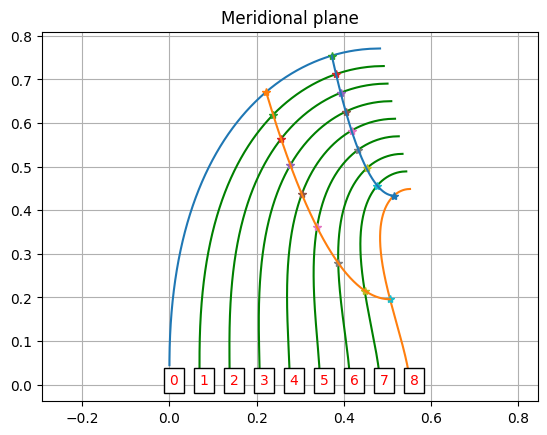

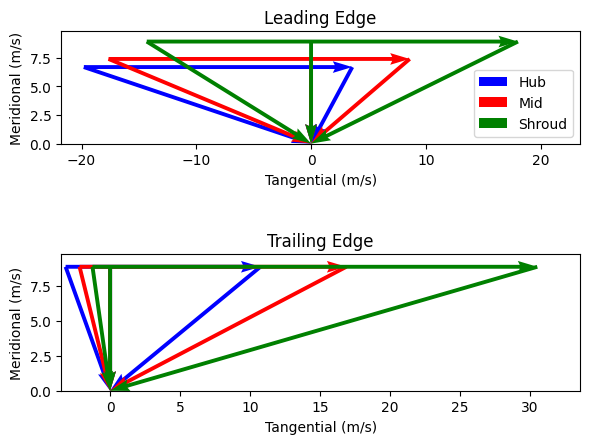

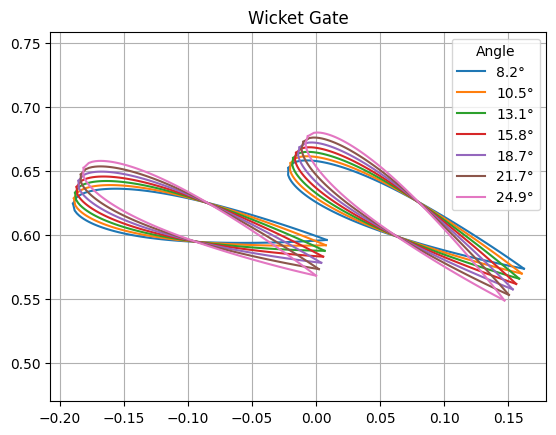

<IPython.core.display.Javascript object>

In [ ]:
#@title Inputs
Vo = 6.9 # m^3/s
H = 47.9 # m
nrpm = 600 # rpm
nr = 2 * np.pi * nrpm / 60  # rad/s
Z = 24 # Number of WGs
chord = 0.2 # WG profile chord
tkns = 0.18 # NACA 4-digit thickness of the WG profile
N = 7 # Number of streamlines (MUST be odd, to keep one in the middle)
zs = 0 # Suction height, negative if machine is submerged. (From tailwater to runner outlet)
f = 1.03 # Factor to space the wicket gates based on runner diameter

# Partial loads to be calculated a WG opening for
Loads = np.array([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])

# --- CALL PIPELINE ---
dims = merid_dims(Vo, H, nr, N)
lins = merid_lines(dims)
vels = VelTriang(dims, lins, Vo, H, nr, Z, chord, tkns, N, zs, f)
load = partLoad(Vo, Loads, vels, chord)
# printdata(lins, dims)
plotmerid(lins)
plotVelTriang(vels, lins)
plotWG(vels, load.TE_ang)
# dxfCreator(vels, load.WG_angles)

output.no_vertical_scroll()

In [ ]:
ke = (vels.c[:, lins.M]*vels.adim)**2 / (2*9.81)
p = H - ke
p[2] = .15*H - ke[2]
# print(f'Ke = {ke} m')
# print(f'p = {p} m')


alpha1 = np.rad2deg(np.arctan(vels.cu[1, :]/vels.cm[1, :]))
print(alpha1)

mu = vels.cm[1, lins.M]/vels.cm[2, lins.M]
print(mu)

[71.38047271 70.64175019 69.7327631  68.63186135 67.30919067 65.72041992
 63.79436737 61.40561305 58.15003073]
0.8328303198527943
